# Task 4 - Channel effectiveness, measured

Data: `channel_trials.csv` (30 rows: 5 channels x 6 true ratios) and `iris.csv`.
A very small reproduction of Cleveland & McGill: one reader, 30 judgements.

Reader rules: no numbers anywhere on the charts, trial order shuffled, no feedback until the very end.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import clear_output

TRIALS_FILE = "channel_trials.csv"
RESULTS_FILE = "channel_results.csv"

trials = pd.read_csv(TRIALS_FILE)
VMAX = max(trials["value_large"].max(), trials["value_small"].max())  # one shared scale for every chart

# Cleveland & McGill order (best to worst). Volume was not part of our five.
PUBLISHED = ["position", "length", "angle", "area", "colour"]
trials.head()

,trial,channel,true_ratio,value_large,value_small,reader_estimate,absolute_error
0,1,position,0.15,76,11.40,NaN,NaN
1,2,position,0.25,59,14.75,NaN,NaN
2,3,position,0.40,76,30.40,NaN,NaN
3,4,position,0.55,68,37.40,NaN,NaN
4,5,position,0.70,61,42.70,NaN,NaN


## 1. Encode each trial five ways
Five tiny chart functions, one channel each. No axis labels, no tick values, no numbers.

- **position:** two dots on a common scale (thin grey line = the zero of the scale, no number on it)
- **length:** two bars from a common zero baseline
- **angle:** two wedges of one pie
- **area:** two circles, area proportional to value. In `ax.scatter`, `s` **is** area. I set `s` proportional to the value
  (not the value squared), so area is proportional to the value. No area lie.
- **colour:** two squares on a sequential lightness ramp (Greys, bigger value = darker). Not a rainbow.

In [2]:
def draw_position(ax, a, b):
    ax.hlines(0, -0.7, 1.7, color="lightgrey", linewidth=1)
    ax.scatter([0, 1], [a, b], s=140, color="black", zorder=3)
    ax.set_xlim(-0.9, 1.9)
    ax.set_ylim(-0.04 * VMAX, 1.1 * VMAX)
    ax.axis("off")


def draw_length(ax, a, b):
    ax.bar([0, 1], [a, b], width=0.5, color="black")
    ax.set_xlim(-0.9, 1.9)
    ax.set_ylim(0, 1.1 * VMAX)
    ax.axis("off")


def draw_angle(ax, a, b):
    # two wedges of one pie: the wedge angles are in the ratio a : b
    ax.pie([a, b], colors=["0.25", "0.75"], startangle=90, counterclock=False,
           wedgeprops=dict(edgecolor="white", linewidth=1.5))
    ax.axis("off")


S_MAX = 3500  # marker area (points^2) for the biggest value in the whole file


def draw_area(ax, a, b):
    # s IS area. s proportional to value (NOT value squared) -> area proportional to value.
    ax.scatter([0, 2], [0, 0], s=[a / VMAX * S_MAX, b / VMAX * S_MAX], color="black")
    ax.set_xlim(-1.2, 3.2)
    ax.set_ylim(-1.5, 1.5)
    ax.axis("off")


def draw_colour(ax, a, b):
    ramp = matplotlib.colormaps["Greys"]
    for x, v in [(0, a), (1.4, b)]:
        ax.add_patch(Rectangle((x, 0), 1, 1, facecolor=ramp(0.08 + 0.92 * v / VMAX), edgecolor="none"))
    ax.set_xlim(-0.3, 2.7)
    ax.set_ylim(-0.7, 1.7)
    ax.set_aspect("equal")
    ax.axis("off")


DRAW = {"position": draw_position, "length": draw_length, "angle": draw_angle,
        "area": draw_area, "colour": draw_colour}


def draw_trial(ax, channel, large, small, rng):
    # random side for the bigger one, so the reader can't learn "left is bigger"
    a, b = (large, small) if rng.random() < 0.5 else (small, large)
    DRAW[channel](ax, a, b)

Quick look at the five encodings of the same pair (80 and 40) - for you, not for the reader.

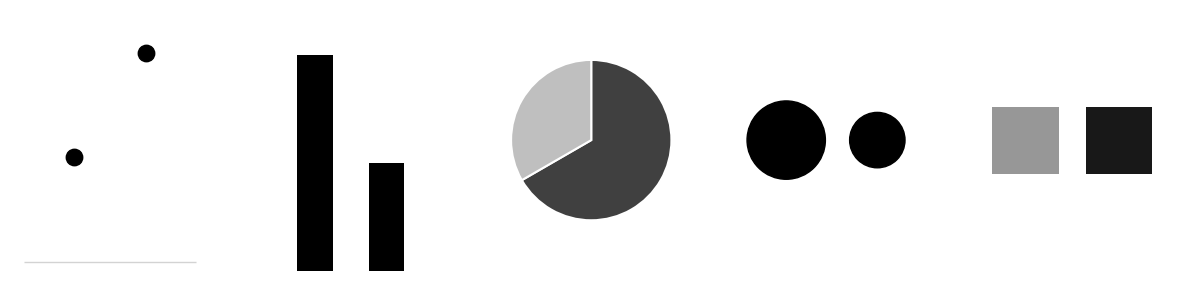

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
demo_rng = np.random.default_rng(0)
for ax, ch in zip(axes, DRAW):
    draw_trial(ax, ch, 80, 40, demo_rng)
plt.show()

## 2. Run all 30 trials on a real person
Each trial: look at the chart, then type the answer to "the smaller one is what percentage of the larger?" (0-100).
Type `q` to stop; run the cell again and it carries on with the blanks. Progress is saved after every trial.

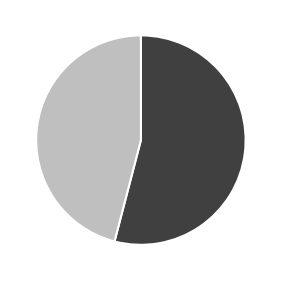

  a number between 0 and 100 please
  a number between 0 and 100 please
  a number between 0 and 100 please
  a number between 0 and 100 please
  a number between 0 and 100 please
  a number between 0 and 100 please
  a number between 0 and 100 please
progress saved


In [4]:
def run_experiment():
    unknown = set(trials["channel"]) - set(DRAW)
    assert not unknown, f"channel names in the csv I don't know how to draw: {unknown}"

    df = pd.read_csv(RESULTS_FILE) if os.path.exists(RESULTS_FILE) else trials.copy()
    todo = df[df["reader_estimate"].isna()].sample(frac=1)  # shuffled order
    if todo.empty:
        print("all trials already have an estimate")
        return df

    rng = np.random.default_rng()
    for k, (i, row) in enumerate(todo.iterrows(), start=1):
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(3.4, 3.4))
        draw_trial(ax, row["channel"], row["value_large"], row["value_small"], rng)
        plt.show()
        plt.close(fig)
        while True:
            answer = input(f"[{k}/{len(todo)}] smaller is what % of larger? (0-100, q to stop) ").strip().lower()
            if answer == "q":
                df.to_csv(RESULTS_FILE, index=False)
                print("progress saved")
                return df
            try:
                est = float(answer)
                if 0 <= est <= 100:
                    break
            except ValueError:
                pass
            print("  a number between 0 and 100 please")
        df.loc[i, "reader_estimate"] = est
        df.to_csv(RESULTS_FILE, index=False)  # save after every trial so nothing is lost

    clear_output()
    df["absolute_error"] = (df["reader_estimate"] / 100 - df["true_ratio"]).abs()
    df.to_csv(RESULTS_FILE, index=False)
    print(f"done, saved {RESULTS_FILE}")
    return df


results = run_experiment()

## 3. Error and ranking
`absolute_error = abs(reader_estimate / 100 - true_ratio)`, saved into `channel_results.csv`.
Bars are sorted, zero baseline, error bars are +/- 1 standard error.

ValueError: Axis limits cannot be NaN or Inf

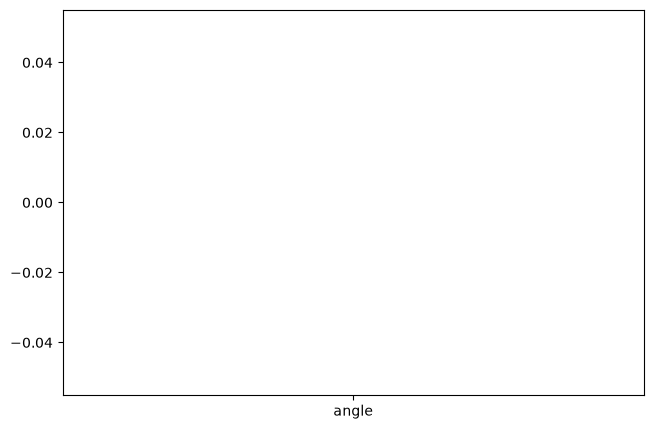

In [5]:
df = pd.read_csv(RESULTS_FILE)
df["absolute_error"] = (df["reader_estimate"] / 100 - df["true_ratio"]).abs()
df.to_csv(RESULTS_FILE, index=False)
if df["absolute_error"].isna().any():
    print("warning: some trials have no estimate yet")

summary = (df.groupby("channel")["absolute_error"]
             .agg(mean="mean", sem="sem", n="count")
             .sort_values("mean"))

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.bar(summary.index, summary["mean"], yerr=summary["sem"], capsize=5, color="#4c72b0", width=0.6)
for x, (m, s) in enumerate(zip(summary["mean"], summary["sem"])):
    ax.text(x, m + s + 0.004, f"{m:.3f}", ha="center", fontsize=9)
ax.set_ylim(0, (summary["mean"] + summary["sem"]).max() * 1.2)  # zero baseline
ax.set_ylabel("Mean absolute error (0.10 = off by 10 percentage points)")
ax.spines[["top", "right"]].set_visible(False)
best, worst = summary.index[0], summary.index[-1]
ax.set_title(f"One reader: {best} gave the smallest error ({summary['mean'].iloc[0]:.2f}), "
             f"{worst} the largest ({summary['mean'].iloc[-1]:.2f})", loc="left", fontsize=11)
ax.text(0, -0.12, f"n = {int(summary['n'].iloc[0])} trials per channel, one reader. "
                  "Error bars are +/- 1 standard error.", transform=ax.transAxes, fontsize=8, color="0.35")
fig.savefig("task4_channel_ranking.png", dpi=300, bbox_inches="tight")
plt.show()
summary.round(3)

In [6]:
mine = list(summary.index)
print("My ranking (best first):       ", " > ".join(mine))
print("Published (volume not tested): ", " > ".join(PUBLISHED))
print("\nchannel      mine  published  difference")
for ch in PUBLISHED:
    m, p = mine.index(ch) + 1, PUBLISHED.index(ch) + 1
    print(f"{ch:10s}  {m:4d}  {p:9d}  {m - p:+d}")

My ranking (best first):        angle > area > colour > length > position
Published (volume not tested):  position > length > angle > area > colour

channel      mine  published  difference
position       5          1  +4
length         4          2  +2
angle          1          3  -2
area           2          4  -2
colour         3          5  -2


**Compared with position > length > angle > area > volume > colour:**
my ranking agrees on [FILL] and disagrees on [FILL]. Likely reasons for the disagreements: [FILL - 6 trials per channel,
one reader, which ratios happened to land on which channel, learning during the session, ...].

## 4. Apply it: iris.csv, petal_length through two channels
Same data, same message, two channels: **position** on a common scale (high rank) against **colour lightness** (low rank).

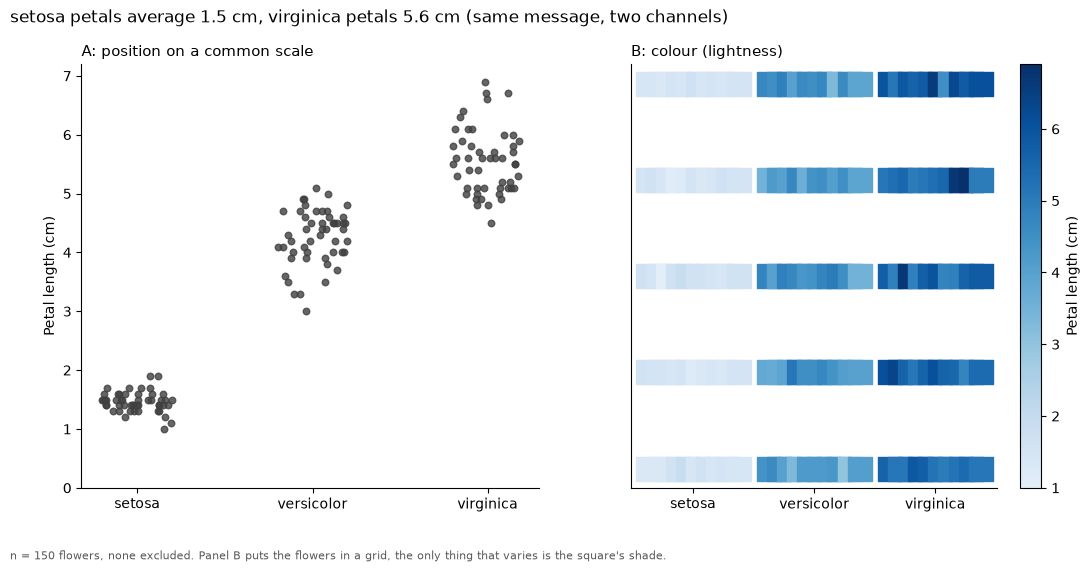

In [7]:
iris = pd.read_csv("iris.csv")
means = iris.groupby("species")["petal_length"].mean().sort_values()
species = list(means.index)  # shortest petals first, longest last
rng = np.random.default_rng(5)  # only for sideways jitter of dots

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 5.5))

# A: petal_length on POSITION (common y scale)
for i, sp in enumerate(species):
    part = iris[iris["species"] == sp]
    ax_a.scatter(i + rng.uniform(-0.2, 0.2, len(part)), part["petal_length"], s=22, color="0.25", alpha=0.8)
ax_a.set_xticks(range(len(species)))
ax_a.set_xticklabels(species)
ax_a.set_ylabel("Petal length (cm)")
ax_a.set_ylim(bottom=0)
ax_a.set_title("A: position on a common scale", loc="left", fontsize=11)

# B: same flowers, petal_length on COLOUR (lightness). Each flower is a square in a 5 x 10 grid.
ramp = matplotlib.colormaps["Blues"]
norm = matplotlib.colors.Normalize(vmin=iris["petal_length"].min(), vmax=iris["petal_length"].max())
for i, sp in enumerate(species):
    part = iris[iris["species"] == sp].reset_index(drop=True)
    xs = i * 12 + (part.index % 10)
    ys = -(part.index // 10)
    ax_b.scatter(xs, ys, s=300, marker="s", c=ramp(0.1 + 0.9 * norm(part["petal_length"])))
ax_b.set_xticks([i * 12 + 4.5 for i in range(len(species))])
ax_b.set_xticklabels(species)
ax_b.set_yticks([])
ax_b.set_title("B: colour (lightness)", loc="left", fontsize=11)
sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=matplotlib.colors.ListedColormap(ramp(np.linspace(0.1, 1, 256))))
fig.colorbar(sm, ax=ax_b, label="Petal length (cm)")
for ax in (ax_a, ax_b):
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"{species[0]} petals average {means.iloc[0]:.1f} cm, {species[-1]} petals {means.iloc[-1]:.1f} cm "
             f"(same message, two channels)", x=0.07, ha="left", fontsize=12)
fig.text(0.07, -0.02, f"n = {len(iris)} flowers, none excluded. Panel B puts the flowers in a grid, "
                      "the only thing that varies is the square's shade.", fontsize=8, color="0.35")
fig.savefig("task4_iris_two_channels.png", dpi=300, bbox_inches="tight")
plt.show()

Visual Encoding Efficacy (Spatial Position vs. Color Lightness)*

* *Theoretical Background:* Validates William S. Cleveland and Robert McGill’s graphical perception hierarchy (1984), which ranks the human eye's accuracy across visual channels: *Position on a common scale $>$ Length $>$ Angle $>$ Area $>$ Color Saturation/Lightness*.


* *Dataset:* Fisher's Iris dataset ($n = 150$), analyzing petal length across setosa, versicolor, and virginica.


* *Detailed Breakdown:*
* *Panel A (Position on a Common Scale):*
* Mechanism: Uses a single, shared vertical Y-axis (0 to 7 cm) with horizontal categorical separation.


* Perceptual Accuracy: The reader instantly perceives three non-overlapping distributions: setosa clustering tightly between 1.0–1.9 cm (mean 1.5 cm), versicolor spanning 3.0–5.1 cm, and virginica occupying 4.5–6.9 cm (mean 5.6 cm). Quantitative comparisons are precise and effortless.




* *Panel B (Colour Lightness / Shading Matrix):*
* Mechanism: Encodes the exact same petal length values using shades of blue inside uniform rectangular grids.


* Perceptual Failure: Human vision cannot accurately decode continuous numerical values from color shades alone. Simultaneous contrast effects (adjacent squares skewing perceived shade) and non-linear lightness perception make it nearly impossible to determine whether a blue cell represents 4.2 cm or 5.1 cm.






* *Core Takeaway:* Always encode quantitative data using spatial position along an aligned axis rather than relying on color intensity or shade variations.

**Which one I would publish:** [FILL - A (position), unless your own data says otherwise]. In terms of decoding accuracy,
a reader can judge positions on a common scale more accurately than shades of one colour, and the colour version needs a
colour-bar lookup for every square.

## The question: what can this experiment support?
It has 30 trials (6 per channel) from **one** reader. It can say how *this* person did on *these* six ratios. It cannot
support any claim about people in general, it has no statistical power to separate channels with similar error, and
learning, fatigue and the particular ratios chosen could all change the ranking.

**Why the published ranking is still worth following:** Cleveland & McGill's result comes from many readers and many
trials, and it has been replicated at larger scale (Heer & Bostock, 2010, with crowd-sourced readers). That is much stronger
evidence than a handful of my own judgements, so when my small sample disagrees I treat it as noise or a quirk of my six ratios,
not as a reason to change how I design charts.